Ques1

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Cleaned Text:
 
artificial intelligence is an exciting technology
it helps computers learn from data and solve problems
ai is used in healthcare education and transportation
i enjoy learning ai because it makes technology smarter
artificial intelligence can improve our daily lives


Word Tokens:
 ['artificial', 'intelligence', 'is', 'an', 'exciting', 'technology', '.', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'problems', '.', 'ai', 'is', 'used', 'in', 'healthcare', ',', 'education', ',', 'and', 'transportation', '.', 'i', 'enjoy', 'learning', 'ai', 'because', 'it', 'makes', 'technology', 'smarter', '.', 'artificial', 'intelligence', 'can', 'improve', 'our', 'daily', 'lives', '.']

Sentence Tokens:
 ['\nArtificial intelligence is an exciting technology.', 'It helps computers learn from data and solve problems.', 'AI is used in healthcare, education, and transportation.', 'I enjoy learning AI because it makes technology smarter.', 'Artificial intelligence can 

<Axes: xlabel='Samples', ylabel='Counts'>

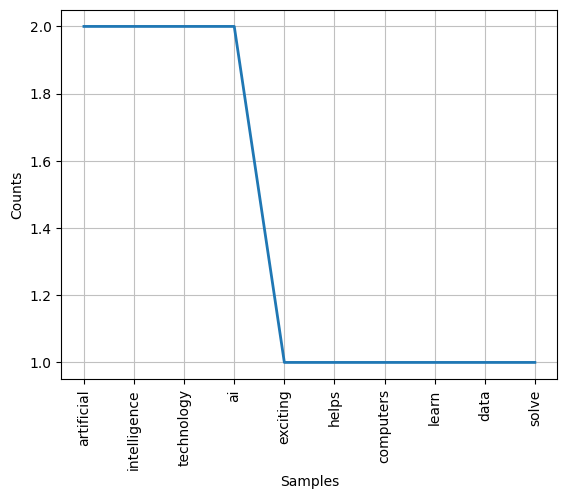

In [1]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Download required NLTK resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Paragraph about Artificial Intelligence
text = """
Artificial intelligence is an exciting technology.
It helps computers learn from data and solve problems.
AI is used in healthcare, education, and transportation.
I enjoy learning AI because it makes technology smarter.
Artificial intelligence can improve our daily lives.
"""

# 1. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("Cleaned Text:\n", clean_text)

# 2. Tokenize into words and sentences
words = word_tokenize(text.lower())
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

# 3. Compare split() and word_tokenize()
print("\nUsing split():\n", text.split())
print("\nUsing word_tokenize():\n", word_tokenize(text))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [
    word for word in word_tokenize(clean_text)
    if word.isalpha() and word not in stop_words
]
print("\nWords after Stopword Removal:\n", filtered_words)

# 5. Display word frequency
frequency = FreqDist(filtered_words)
print("\nWord Frequency Distribution:")
print(frequency.most_common())
frequency.plot(10)

Ques2

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Download resources
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Same paragraph used in Q1
text = """
Artificial intelligence is an exciting technology.
It helps computers learn from data and solve problems.
AI is used in healthcare, education, and transportation.
I enjoy learning AI because it makes technology smarter.
Artificial intelligence can improve our daily lives.
"""

# 1. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Alphabetic Words:\n", words)

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nAfter Stopword Removal:\n", filtered_words)

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words]
print("\nStemmed Words:\n", stemmed_words)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]
print("\nLemmatized Words:\n", lemmatized_words)

# 5. Comparison
print("\nComparison:")
for original, stem, lemma in zip(
    filtered_words, stemmed_words, lemmatized_words
):
    print(original, "-> Stem:", stem, "| Lemma:", lemma)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Alphabetic Words:
 ['artificial', 'intelligence', 'is', 'an', 'exciting', 'technology', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'problems', 'ai', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'i', 'enjoy', 'learning', 'ai', 'because', 'it', 'makes', 'technology', 'smarter', 'artificial', 'intelligence', 'can', 'improve', 'our', 'daily', 'lives']

After Stopword Removal:
 ['artificial', 'intelligence', 'exciting', 'technology', 'helps', 'computers', 'learn', 'data', 'solve', 'problems', 'ai', 'used', 'healthcare', 'education', 'transportation', 'enjoy', 'learning', 'ai', 'makes', 'technology', 'smarter', 'artificial', 'intelligence', 'improve', 'daily', 'lives']

Stemmed Words:
 ['artifici', 'intellig', 'excit', 'technolog', 'help', 'comput', 'learn', 'data', 'solv', 'problem', 'ai', 'use', 'healthcar', 'educ', 'transport', 'enjoy', 'learn', 'ai', 'make', 'technolog', 'smarter', 'artifici', 'intellig', 'improv', 'daili', 'live']

Le

Ques3

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three short texts
documents = [
    "Artificial intelligence helps students learn faster",
    "Machine learning helps computers analyze data",
    "Artificial intelligence and machine learning are useful"
]

# 1. Bag of Words
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(documents)

print("Vocabulary:")
print(count_vectorizer.get_feature_names_out())

print("\nBag of Words Matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray().round(3))

# 3. Top 3 keywords from each text
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\nTop 3 Keywords from Each Text:")
for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[::-1][:3]
    keywords = [
        (feature_names[j], round(row[j], 3))
        for j in top_indices
    ]
    print(f"Text {i + 1}: {keywords}")

Vocabulary:
['analyze' 'and' 'are' 'artificial' 'computers' 'data' 'faster' 'helps'
 'intelligence' 'learn' 'learning' 'machine' 'students' 'useful']

Bag of Words Matrix:
[[0 0 0 1 0 0 1 1 1 1 0 0 1 0]
 [1 0 0 0 1 1 0 1 0 0 1 1 0 0]
 [0 1 1 1 0 0 0 0 1 0 1 1 0 1]]

TF-IDF Matrix:
[[0.    0.    0.    0.349 0.    0.    0.46  0.349 0.349 0.46  0.    0.
  0.46  0.   ]
 [0.46  0.    0.    0.    0.46  0.46  0.    0.349 0.    0.    0.349 0.349
  0.    0.   ]
 [0.    0.434 0.434 0.33  0.    0.    0.    0.    0.33  0.    0.33  0.33
  0.    0.434]]

Top 3 Keywords from Each Text:
Text 1: [('students', np.float64(0.46)), ('learn', np.float64(0.46)), ('faster', np.float64(0.46))]
Text 2: [('data', np.float64(0.46)), ('computers', np.float64(0.46)), ('analyze', np.float64(0.46))]
Text 3: [('useful', np.float64(0.434)), ('and', np.float64(0.434)), ('are', np.float64(0.434))]


Ques4

In [4]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two short texts
text1 = """
Artificial intelligence allows computers to learn from data.
AI helps automate tasks and solve complex problems.
Machine learning improves prediction and decision making.
AI is widely used in healthcare and education.
"""

text2 = """
Blockchain stores data in secure distributed blocks.
It supports transparent transactions and digital currencies.
Blockchain improves security and prevents unauthorized changes.
It is used in finance and supply chain management.
"""

# 1. Preprocessing and tokenization
def preprocess(text):
    return re.findall(r'\b[a-zA-Z]+\b', text.lower())

words1 = preprocess(text1)
words2 = preprocess(text2)

print("AI Tokens:\n", words1)
print("\nBlockchain Tokens:\n", words2)

# 2(a). Jaccard Similarity
set1 = set(words1)
set2 = set(words2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nCommon Words:", intersection)
print("Jaccard Similarity:", round(jaccard, 3))

# 2(b). Cosine Similarity using TF-IDF
texts = [text1, text2]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 3))

# 2(c). Analysis
print("\nAnalysis:")
print("Jaccard measures the overlap between unique words.")
print("Cosine similarity compares the TF-IDF weighted word vectors.")
print("The better metric depends on whether word overlap or")
print("weighted word importance is more useful for the task.")

AI Tokens:
 ['artificial', 'intelligence', 'allows', 'computers', 'to', 'learn', 'from', 'data', 'ai', 'helps', 'automate', 'tasks', 'and', 'solve', 'complex', 'problems', 'machine', 'learning', 'improves', 'prediction', 'and', 'decision', 'making', 'ai', 'is', 'widely', 'used', 'in', 'healthcare', 'and', 'education']

Blockchain Tokens:
 ['blockchain', 'stores', 'data', 'in', 'secure', 'distributed', 'blocks', 'it', 'supports', 'transparent', 'transactions', 'and', 'digital', 'currencies', 'blockchain', 'improves', 'security', 'and', 'prevents', 'unauthorized', 'changes', 'it', 'is', 'used', 'in', 'finance', 'and', 'supply', 'chain', 'management']

Common Words: {'used', 'in', 'improves', 'and', 'is', 'data'}
Jaccard Similarity: 0.128
Cosine Similarity: 0.231

Analysis:
Jaccard measures the overlap between unique words.
Cosine similarity compares the TF-IDF weighted word vectors.
The better metric depends on whether word overlap or
weighted word importance is more useful for the task.

Ques5

In [5]:
!pip install vaderSentiment wordcloud matplotlib


Review 1: This phone has an amazing camera and excellent battery life.
Positive score: 0.484
Negative score: 0.0
Neutral score: 0.516
Compound polarity: 0.8176
Sentiment: Positive

Review 2: The product is terrible and the battery drains very quickly.
Positive score: 0.0
Negative score: 0.256
Neutral score: 0.744
Compound polarity: -0.4767
Sentiment: Negative

Review 3: The phone is okay and has average features.
Positive score: 0.213
Negative score: 0.0
Neutral score: 0.787
Compound polarity: 0.2263
Sentiment: Positive


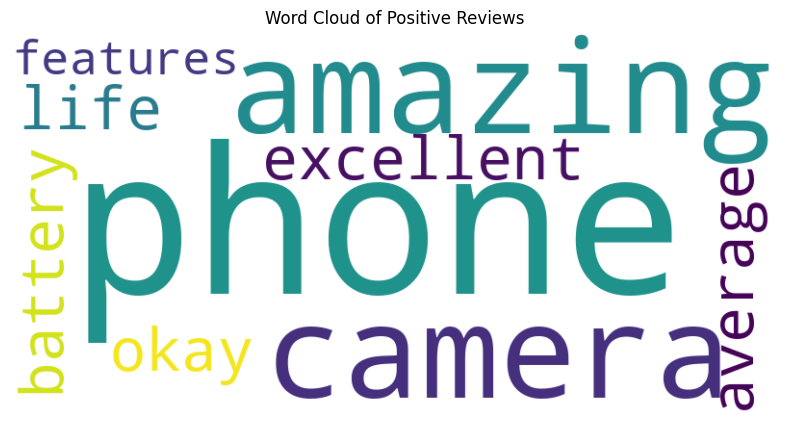

In [6]:
import nltk
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

# 1. Product reviews
reviews = [
    "This phone has an amazing camera and excellent battery life.",
    "The product is terrible and the battery drains very quickly.",
    "The phone is okay and has average features."
]

# 2. Initialize sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

positive_reviews = []

# 3. Find polarity and classify reviews
for i, review in enumerate(reviews, start=1):
    scores = analyzer.polarity_scores(review)
    compound = scores['compound']

    if compound >= 0.05:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {i}: {review}")
    print("Positive score:", scores['pos'])
    print("Negative score:", scores['neg'])
    print("Neutral score:", scores['neu'])
    print("Compound polarity:", scores['compound'])
    print("Sentiment:", sentiment)

# 4. Create word cloud from positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews available.")

Ques6

In [11]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
text = """
Technology is changing the world every day.
Artificial intelligence helps people solve difficult problems.
Computers can learn from data and improve their performance.
Students use technology to learn new skills and explore ideas.
Machine learning is useful in healthcare, education, and business.
Programming teaches logical thinking and problem solving.
Python is a popular language for artificial intelligence.
Developers create applications that make everyday tasks easier.
Technology connects people and provides access to information.
Learning new technologies can create exciting career opportunities.
Students should practice coding regularly to improve their skills.
Artificial intelligence can support human creativity and innovation.
The future of technology depends on responsible development.
People can use technology to build a better world.
"""

# 2. Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
print("Total unique words:", total_words)

# 3. Create input sequences
input_sequences = []

for line in text.lower().split('.'):
    line = line.strip()

    if not line:
        continue

    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        sequence = token_list[:i + 1]
        input_sequences.append(sequence)

# 4. Pad sequences
max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

# 5. Separate input and output
X = input_sequences[:, :-1]
y = input_sequences[:, -1]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

# 6. Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=32
    ),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

# Build model before displaying summary
model.build(input_shape=(None, max_sequence_len - 1))

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# 7. Train the model
print("\nTraining the model...")
model.fit(X, y, epochs=30, verbose=1)

print("\nModel training completed!")

# 8. Generate new text

def generate_text(seed_text, next_words=8):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=max_sequence_len - 1,
            padding='pre',
            truncating='pre'
        )

        predictions = model.predict(token_list, verbose=0)[0]

        # Prevent selection of padding index 0
        predictions[0] = 0

        # Reduce repetition of words already in the generated text
        for word in seed_text.lower().split():
            word_index = tokenizer.word_index.get(word)
            if word_index is not None:
                predictions[word_index] *= 0.5

        # Normalize probabilities
        if predictions.sum() == 0:
            break

        predictions = predictions / predictions.sum()

        # Select the next word randomly using probabilities
        predicted_word_index = np.random.choice(
            len(predictions), p=predictions
        )

        output_word = None
        for word, index in tokenizer.word_index.items():
            if index == predicted_word_index:
                output_word = word
                break

        if output_word is None:
            continue

        seed_text += " " + output_word

    return seed_text

print("\nGenerated Text:")
print("Line 1:", generate_text("technology", 8))
print("Line 2:", generate_text("artificial intelligence", 8))
print("Line 3:", generate_text("students", 8))

Total unique words: 81
Input shape: (101, 9)
Output shape: (101,)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 9, 32)          │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 81)             │         5,265 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,689 (127.69 KB)

 Trainable params: 32,689 (127.69 KB)

 Non-trainable params: 0 (0.00 B)


Training the model...
Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.0099 - loss: 4.3958  
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0594 - loss: 4.3893
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0693 - loss: 4.3844
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0792 - loss: 4.3791
Epoch 5/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.0792 - loss: 4.3733
Epoch 6/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0594 - loss: 4.3661
Epoch 7/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0594 - loss: 4.3565
Epoch 8/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.0594 - loss: 4.3412
Epoch 9/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0594 - loss: 4.3190
Epoch 10/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0594 - loss: 4.2835
Epoch 11/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0594 - loss: 4.2306
Epoch 12/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy